### (1) \(S\)-statistic with Iterative Inpainting

\(S\)-statistic results for the E1 \(r000\) map after iterative inpainting, using **100 independent inpainting realisations**.

S 95.4% column: S_crit_filtered_95p4
S 99.7% column: S_crit_filtered_99p7
D 95.4% column: D_floor_filtered_95p4
179.0: loaded ip000
179.0: loaded ip001
179.0: loaded ip002
179.0: loaded ip003
179.0: loaded ip004
179.0: loaded ip005
179.0: loaded ip006
179.0: loaded ip007
179.0: loaded ip008
179.0: loaded ip009
179.0: loaded ip010
179.0: loaded ip011
179.0: loaded ip012
179.0: loaded ip013
179.0: loaded ip014
179.0: loaded ip015
179.0: loaded ip016
179.0: loaded ip017
179.0: loaded ip018
179.0: loaded ip019
179.0: loaded ip020
179.0: loaded ip021
179.0: loaded ip022
179.0: loaded ip023
179.0: loaded ip024
179.0: loaded ip025
179.0: loaded ip026
179.0: loaded ip027
179.0: loaded ip028
179.0: loaded ip029
179.0: loaded ip030
179.0: loaded ip031
179.0: loaded ip032
179.0: loaded ip033
179.0: loaded ip034
179.0: loaded ip035
179.0: loaded ip036
179.0: loaded ip037
179.0: loaded ip038
179.0: loaded ip039
179.0: loaded ip040
179.0: loaded ip041
179.0: loaded ip042
179.0: loaded ip043
179.0: l

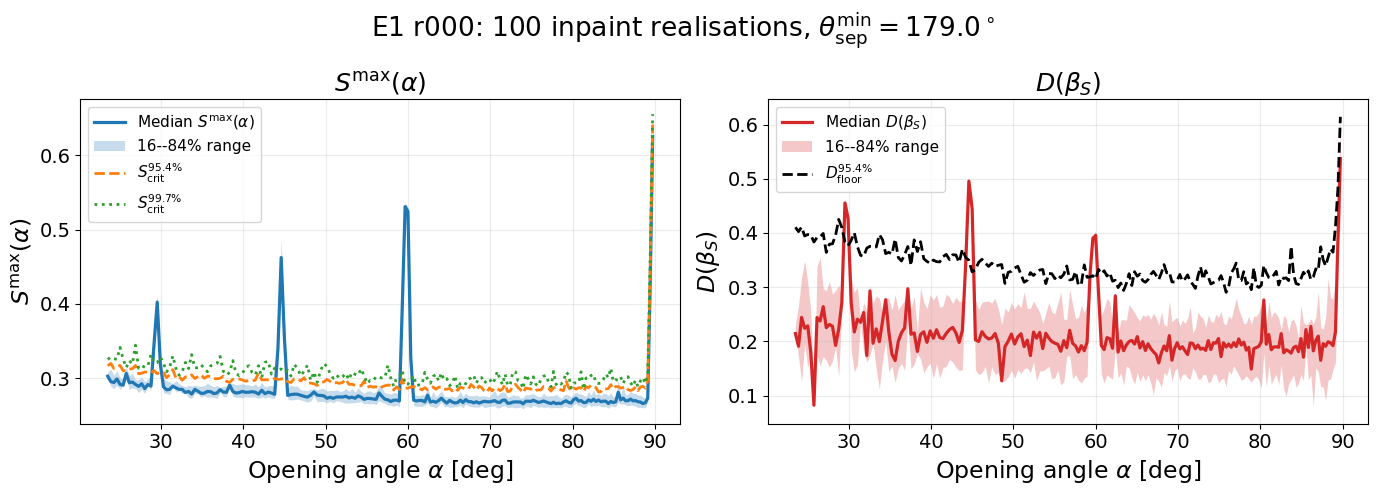

Saved: /hydrarepo/xluo/circles-in-the-sky/e1_ip100/plots_r000_100inpaints_median/E1_r000_100inpaints_S_and_D_179p0_median.png
179.5: loaded ip000
179.5: loaded ip001
179.5: loaded ip002
179.5: loaded ip003
179.5: loaded ip004
179.5: loaded ip005
179.5: loaded ip006
179.5: loaded ip007
179.5: loaded ip008
179.5: loaded ip009
179.5: loaded ip010
179.5: loaded ip011
179.5: loaded ip012
179.5: loaded ip013
179.5: loaded ip014
179.5: loaded ip015
179.5: loaded ip016
179.5: loaded ip017
179.5: loaded ip018
179.5: loaded ip019
179.5: loaded ip020
179.5: loaded ip021
179.5: loaded ip022
179.5: loaded ip023
179.5: loaded ip024
179.5: loaded ip025
179.5: loaded ip026
179.5: loaded ip027
179.5: loaded ip028
179.5: loaded ip029
179.5: loaded ip030
179.5: loaded ip031
179.5: loaded ip032
179.5: loaded ip033
179.5: loaded ip034
179.5: loaded ip035
179.5: loaded ip036
179.5: loaded ip037
179.5: loaded ip038
179.5: loaded ip039
179.5: loaded ip040
179.5: loaded ip041
179.5: loaded ip042
179.5: loaded 

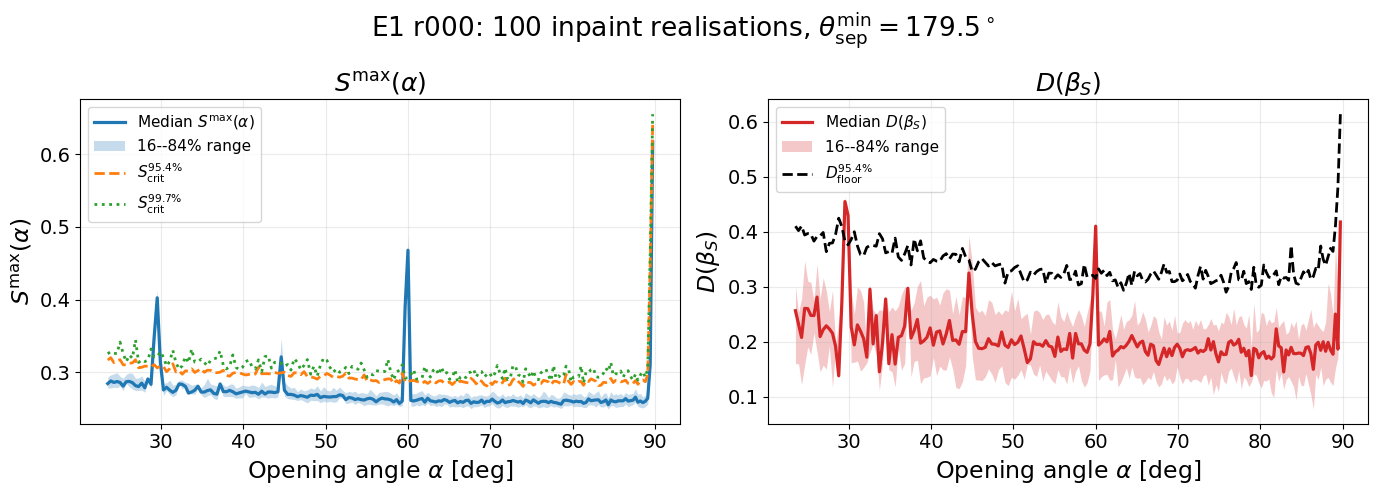

Saved: /hydrarepo/xluo/circles-in-the-sky/e1_ip100/plots_r000_100inpaints_median/E1_r000_100inpaints_S_and_D_179p5_median.png

Finished.
Plots saved in: /hydrarepo/xluo/circles-in-the-sky/e1_ip100/plots_r000_100inpaints_median


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ==================================================
# Paths
# ==================================================

root = Path("/hydrarepo/xluo/circles-in-the-sky")

results_179p0 = (
    root
    / "e1_ip100_sd_sep179p0"
    / "results"
)

results_179p5 = (
    root
    / "e1_ip100_sd_sep179p5"
    / "results"
)

s_critical_file = (
    root
    / "null_unfiltered_S_critical"
    / "S_critical_unfiltered_95p4_99p7_by_alpha.dat"
)

d_floor_file = (
    root
    / "null_ipf_filtered_D_at_S_plots"
    / "D_floor_filtered_95p4_99p7_by_alpha.dat"
)

plot_dir = (
    root
    / "e1_ip100"
    / "plots_r000_100inpaints_median"
)

plot_dir.mkdir(
    parents=True,
    exist_ok=True,
)


# ==================================================
# Read one main S or D result
#
# Main files:
#   column 0 = alpha_deg
#   column 1 = statistic
# ==================================================

def read_statistic_file(
    path,
    statistic_name,
):

    if not path.is_file():
        raise FileNotFoundError(path)

    data = np.loadtxt(
        path,
        comments="#",
        usecols=(0, 1),
        ndmin=2,
    )

    rows = pd.DataFrame(
        data,
        columns=[
            "alpha_deg",
            statistic_name,
        ],
    )

    rows = rows.replace(
        [np.inf, -np.inf],
        np.nan,
    )

    rows = rows.dropna(
        subset=[
            "alpha_deg",
            statistic_name,
        ]
    )

    # Normally one row per alpha.
    # If duplicates exist, retain the final output row.
    rows = (
        rows
        .drop_duplicates(
            subset="alpha_deg",
            keep="last",
        )
        .sort_values("alpha_deg")
        .reset_index(drop=True)
    )

    return rows


# ==================================================
# Read one inpaint
# ==================================================

def read_one_inpaint(
    results_dir,
    ip,
):

    s_file = (
        results_dir
        / f"e1r000_ip{ip:03d}.dat"
    )

    d_file = (
        results_dir
        / f"e1r000_ip{ip:03d}_d.dat"
    )

    s_rows = read_statistic_file(
        path=s_file,
        statistic_name="Smax",
    )

    d_rows = read_statistic_file(
        path=d_file,
        statistic_name="D_at_betaS",
    )

    rows = pd.merge(
        s_rows,
        d_rows,
        on="alpha_deg",
        how="inner",
        validate="one_to_one",
    )

    if len(rows) != len(s_rows):
        raise RuntimeError(
            f"ip{ip:03d}: S and D alpha grids "
            "do not match."
        )

    rows.insert(
        0,
        "inpaint",
        ip,
    )

    return rows


# ==================================================
# Read 100 inpaint realisations
# ==================================================

def read_100_inpaints(
    results_dir,
    label,
):

    all_rows = []

    for ip in range(100):

        rows = read_one_inpaint(
            results_dir=results_dir,
            ip=ip,
        )

        all_rows.append(rows)

        print(
            f"{label}: loaded ip{ip:03d}",
            flush=True,
        )

    all_results = pd.concat(
        all_rows,
        ignore_index=True,
    )

    if all_results["inpaint"].nunique() != 100:
        raise RuntimeError(
            f"{label}: expected 100 unique "
            "inpaint realisations."
        )

    summary = (
        all_results
        .groupby(
            "alpha_deg",
            as_index=False,
        )
        .agg(
            S_median=(
                "Smax",
                "median",
            ),
            S_p16=(
                "Smax",
                lambda x: x.quantile(0.16),
            ),
            S_p84=(
                "Smax",
                lambda x: x.quantile(0.84),
            ),
            D_median=(
                "D_at_betaS",
                "median",
            ),
            D_p16=(
                "D_at_betaS",
                lambda x: x.quantile(0.16),
            ),
            D_p84=(
                "D_at_betaS",
                lambda x: x.quantile(0.84),
            ),
        )
        .sort_values("alpha_deg")
        .reset_index(drop=True)
    )

    return all_results, summary


# ==================================================
# Read critical curves
# ==================================================

if not s_critical_file.is_file():
    raise FileNotFoundError(s_critical_file)

if not d_floor_file.is_file():
    raise FileNotFoundError(d_floor_file)

s_critical = pd.read_csv(
    s_critical_file,
    sep=r"\s+",
)

d_floor = pd.read_csv(
    d_floor_file,
    sep=r"\s+",
)

s_95_col = next(
    column
    for column in s_critical.columns
    if "95p4" in column.lower()
)

s_99_col = next(
    column
    for column in s_critical.columns
    if "99p7" in column.lower()
)

d_95_col = next(
    column
    for column in d_floor.columns
    if "95p4" in column.lower()
)

print("S 95.4% column:", s_95_col)
print("S 99.7% column:", s_99_col)
print("D 95.4% column:", d_95_col)


# ==================================================
# Plot S and D
# ==================================================

def plot_summary(
    summary,
    separation,
    output_name,
):

    alpha = summary["alpha_deg"].to_numpy()

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(14, 5),
        sharex=True,
    )

    # ----------------------------------------------
    # S panel
    # ----------------------------------------------

    axes[0].plot(
        alpha,
        summary["S_median"],
        color="tab:blue",
        linewidth=2.3,
        label=r"Median $S^{\max}(\alpha)$",
    )

    axes[0].fill_between(
        alpha,
        summary["S_p16"],
        summary["S_p84"],
        color="tab:blue",
        alpha=0.25,
        linewidth=0,
        label="16--84% range",
    )

    axes[0].plot(
        s_critical["alpha_deg"],
        s_critical[s_95_col],
        color="tab:orange",
        linestyle="--",
        linewidth=2,
        label=r"$S_{\rm crit}^{95.4\%}$",
    )

    axes[0].plot(
        s_critical["alpha_deg"],
        s_critical[s_99_col],
        color="tab:green",
        linestyle=":",
        linewidth=2,
        label=r"$S_{\rm crit}^{99.7\%}$",
    )

    axes[0].set_title(
        r"$S^{\max}(\alpha)$",
        fontsize=18,
    )

    axes[0].set_ylabel(
        r"$S^{\max}(\alpha)$",
        fontsize=17,
    )

    # ----------------------------------------------
    # D panel
    # ----------------------------------------------

    axes[1].plot(
        alpha,
        summary["D_median"],
        color="tab:red",
        linewidth=2.3,
        label=r"Median $D(\beta_S)$",
    )

    axes[1].fill_between(
        alpha,
        summary["D_p16"],
        summary["D_p84"],
        color="tab:red",
        alpha=0.25,
        linewidth=0,
        label="16--84% range",
    )

    axes[1].plot(
        d_floor["alpha_deg"],
        d_floor[d_95_col],
        color="black",
        linestyle="--",
        linewidth=2,
        label=r"$D_{\rm floor}^{95.4\%}$",
    )

    axes[1].set_title(
        r"$D(\beta_S)$",
        fontsize=18,
    )

    axes[1].set_ylabel(
        r"$D(\beta_S)$",
        fontsize=17,
    )

    # ----------------------------------------------
    # Shared formatting
    # ----------------------------------------------

    for ax in axes:

        ax.set_xlabel(
            r"Opening angle $\alpha\ [\mathrm{deg}]$",
            fontsize=17,
        )

        ax.tick_params(
            axis="both",
            labelsize=14,
        )

        ax.grid(
            alpha=0.25,
        )

        ax.legend(
            fontsize=11,
        )

    fig.suptitle(
        rf"E1 r000: 100 inpaint realisations, "
        rf"$\theta_{{\rm sep}}^{{\min}}"
        rf"={separation}^\circ$",
        fontsize=19,
    )

    fig.tight_layout()

    output_file = plot_dir / output_name

    fig.savefig(
        output_file,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    print("Saved:", output_file)


# ==================================================
# 179.0 degrees
# ==================================================

all_179p0, summary_179p0 = read_100_inpaints(
    results_dir=results_179p0,
    label="179.0",
)

plot_summary(
    summary=summary_179p0,
    separation="179.0",
    output_name=(
        "E1_r000_100inpaints_"
        "S_and_D_179p0_median.png"
    ),
)


# ==================================================
# 179.5 degrees
# ==================================================

all_179p5, summary_179p5 = read_100_inpaints(
    results_dir=results_179p5,
    label="179.5",
)

plot_summary(
    summary=summary_179p5,
    separation="179.5",
    output_name=(
        "E1_r000_100inpaints_"
        "S_and_D_179p5_median.png"
    ),
)

print("\nFinished.")
print("Plots saved in:", plot_dir)

### (2) $D^{\rm diff}$ Test

$D^{\rm diff}$ results using the combined **separation-1 and separation-2 temperature differences**, evaluated across all **10 E1 simulations**.

Valid output files: 40


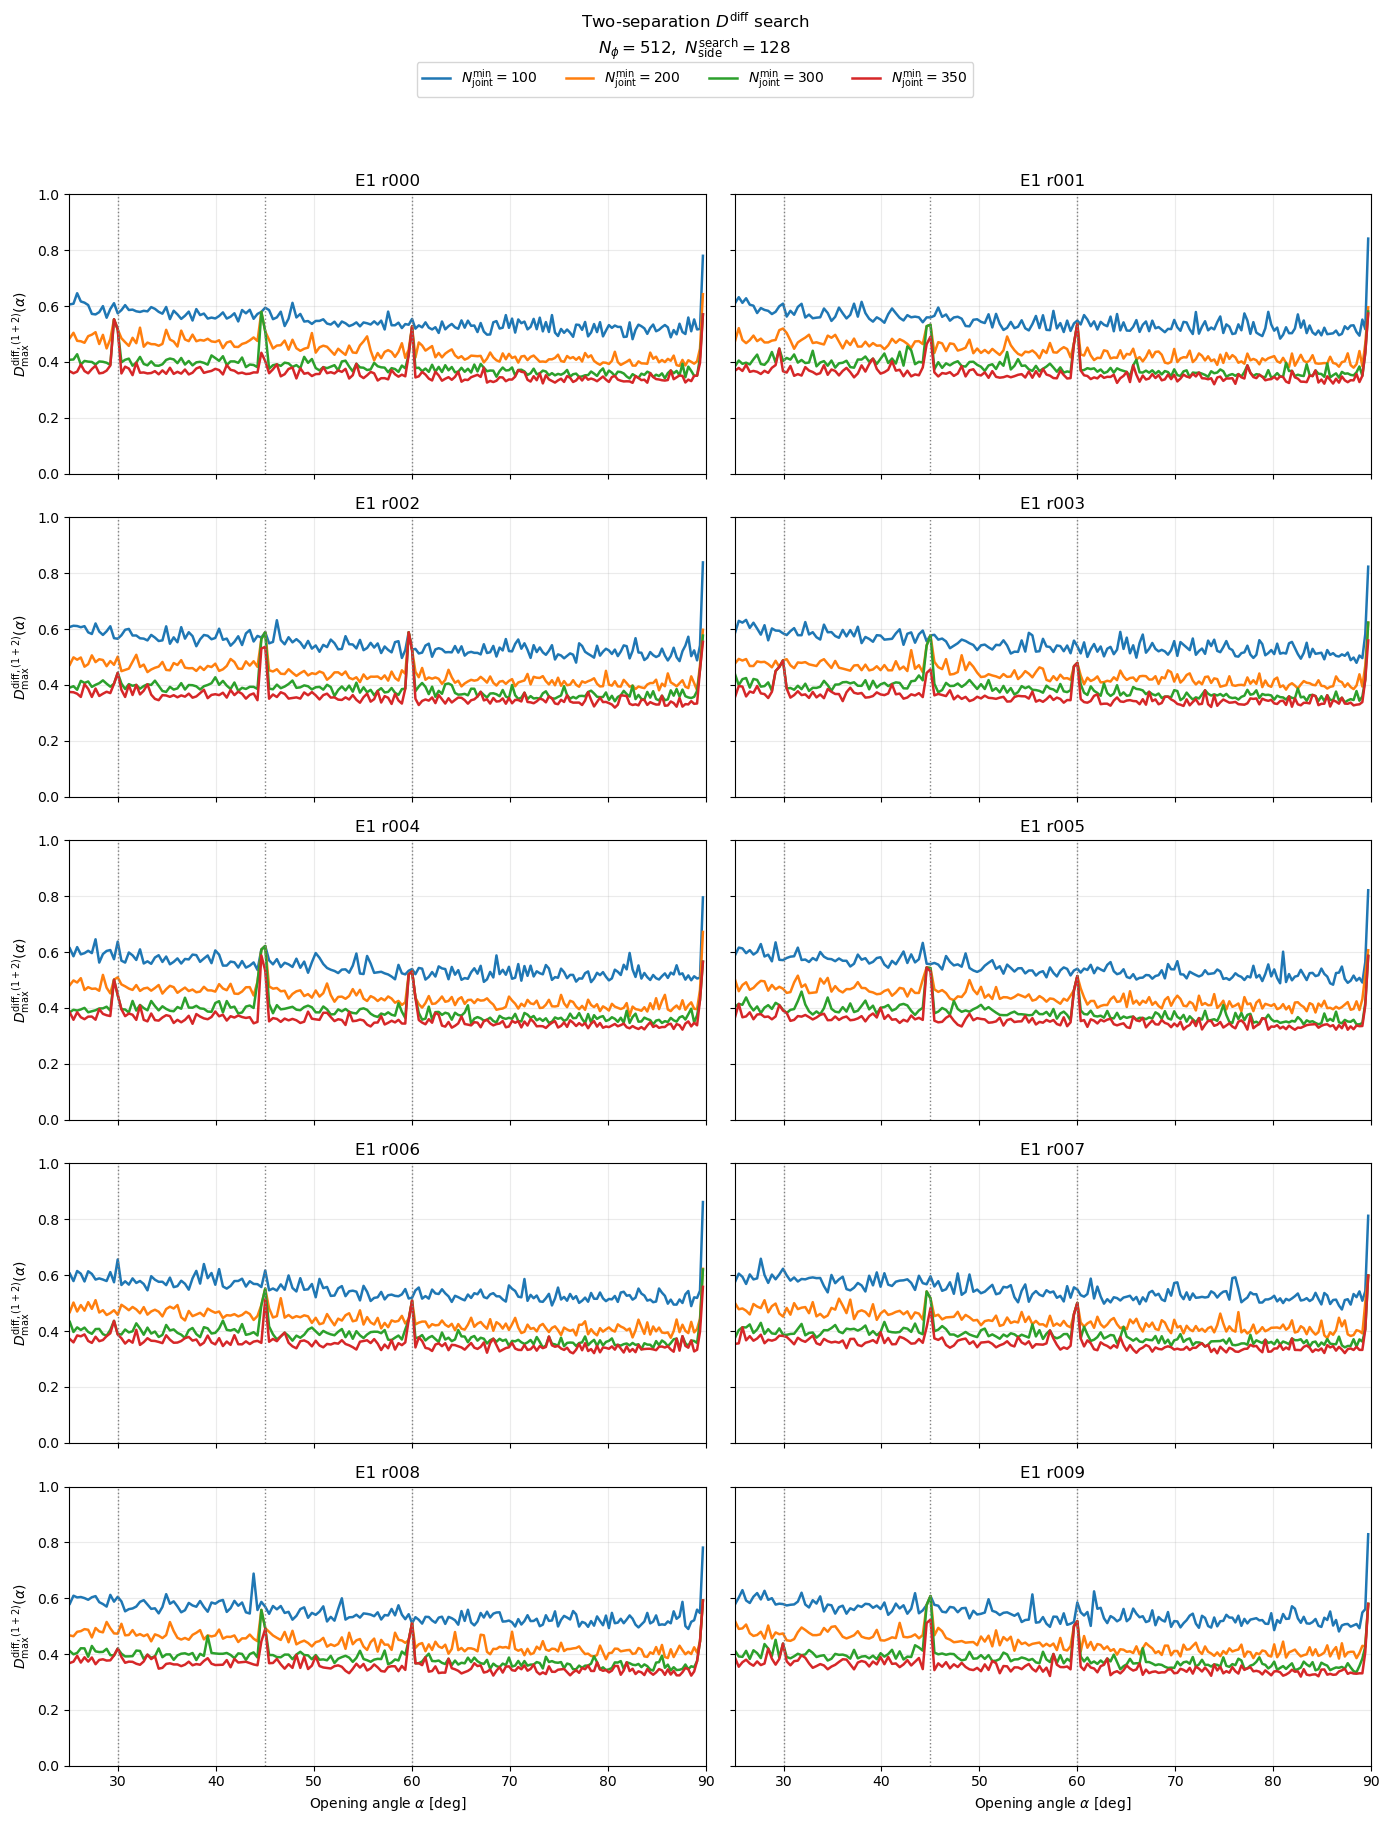

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np


# ==================================================
# Paths and settings
# ==================================================
root = Path(
    "/hydrarepo/xluo/circles-in-the-sky"
)

result_dir = (
    root
    / "e1_d_diff_s12_full"
    / "results"
)

nmins = [
    100,
    200,
    300,
    350,
]

realisations = range(10)


# ==================================================
# Verify all 40 output files
# ==================================================
expected_files = []

for realisation in realisations:

    rr = f"{realisation:03d}"

    for nmin in nmins:

        expected_files.append(
            result_dir
            / (
                f"e1_d_diff_s12_r{rr}"
                f"_n{nmin}_d_diff.dat"
            )
        )


missing_files = [
    file
    for file in expected_files
    if not file.exists()
]

empty_files = [
    file
    for file in expected_files
    if file.exists()
    and file.stat().st_size == 0
]


if missing_files:

    raise FileNotFoundError(
        "Missing output files:\n"
        + "\n".join(
            str(file)
            for file in missing_files
        )
    )


if empty_files:

    raise RuntimeError(
        "Empty output files:\n"
        + "\n".join(
            str(file)
            for file in empty_files
        )
    )


print(
    "Valid output files:",
    len(expected_files),
)


# ==================================================
# Plot one panel for each E1 realisation
# ==================================================
fig, axes = plt.subplots(
    5,
    2,
    figsize=(14, 18),
    sharex=True,
    sharey=True,
)

axes = axes.ravel()


for realisation, ax in zip(
    realisations,
    axes,
):

    rr = f"{realisation:03d}"
    alpha_reference = None

    for nmin in nmins:

        file = (
            result_dir
            / (
                f"e1_d_diff_s12_r{rr}"
                f"_n{nmin}_d_diff.dat"
            )
        )

        data = np.loadtxt(
            file,
            ndmin=2,
        )

        alpha = data[:, 0]
        d_diff_max = data[:, 1]

        if alpha_reference is None:

            alpha_reference = alpha

        elif not np.allclose(
            alpha,
            alpha_reference,
        ):

            raise RuntimeError(
                f"Alpha grid mismatch in:\n{file}"
            )

        ax.plot(
            alpha,
            d_diff_max,
            linewidth=1.8,
            label=(
                rf"$N_{{\rm joint}}^{{\rm min}}"
                rf"={nmin}$"
            ),
        )

    for injected_alpha in [
        30,
        45,
        60,
    ]:

        ax.axvline(
            injected_alpha,
            color="0.5",
            linestyle=":",
            linewidth=1,
        )

    ax.set_title(
        f"E1 r{rr}"
    )

    ax.set_xlim(
        25,
        90,
    )

    ax.set_ylim(
        0,
        1,
    )

    ax.grid(
        alpha=0.25
    )


# ==================================================
# Shared labels and legend
# ==================================================
for ax in axes[-2:]:

    ax.set_xlabel(
        r"Opening angle $\alpha$ [deg]"
    )


for ax in axes[::2]:

    ax.set_ylabel(
        r"$D_{\max}^{\rm diff,(1+2)}(\alpha)$"
    )


handles, labels = (
    axes[0].get_legend_handles_labels()
)

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=4,
    frameon=True,
    bbox_to_anchor=(0.5, 0.985),
)


fig.suptitle(
    r"Two-separation $D^{\rm diff}$ search"
    "\n"
    r"$N_\phi=512,\ N_{\rm side}^{\rm search}=128$",
    y=1.01,
)


plt.tight_layout(
    rect=[
        0,
        0,
        1,
        0.965,
    ]
)

plt.show()

### (3) MASTER-like Reconstruction

MASTER-like results for all **10 E1 simulations**. For

$$
25^\circ \leq \alpha \leq 48^\circ,
$$

the SW filter is applied to make the Sachs--Wolfe contribution dominant, while

$$
42^\circ \leq \alpha \leq 90^\circ
$$

is analysed without filtering.

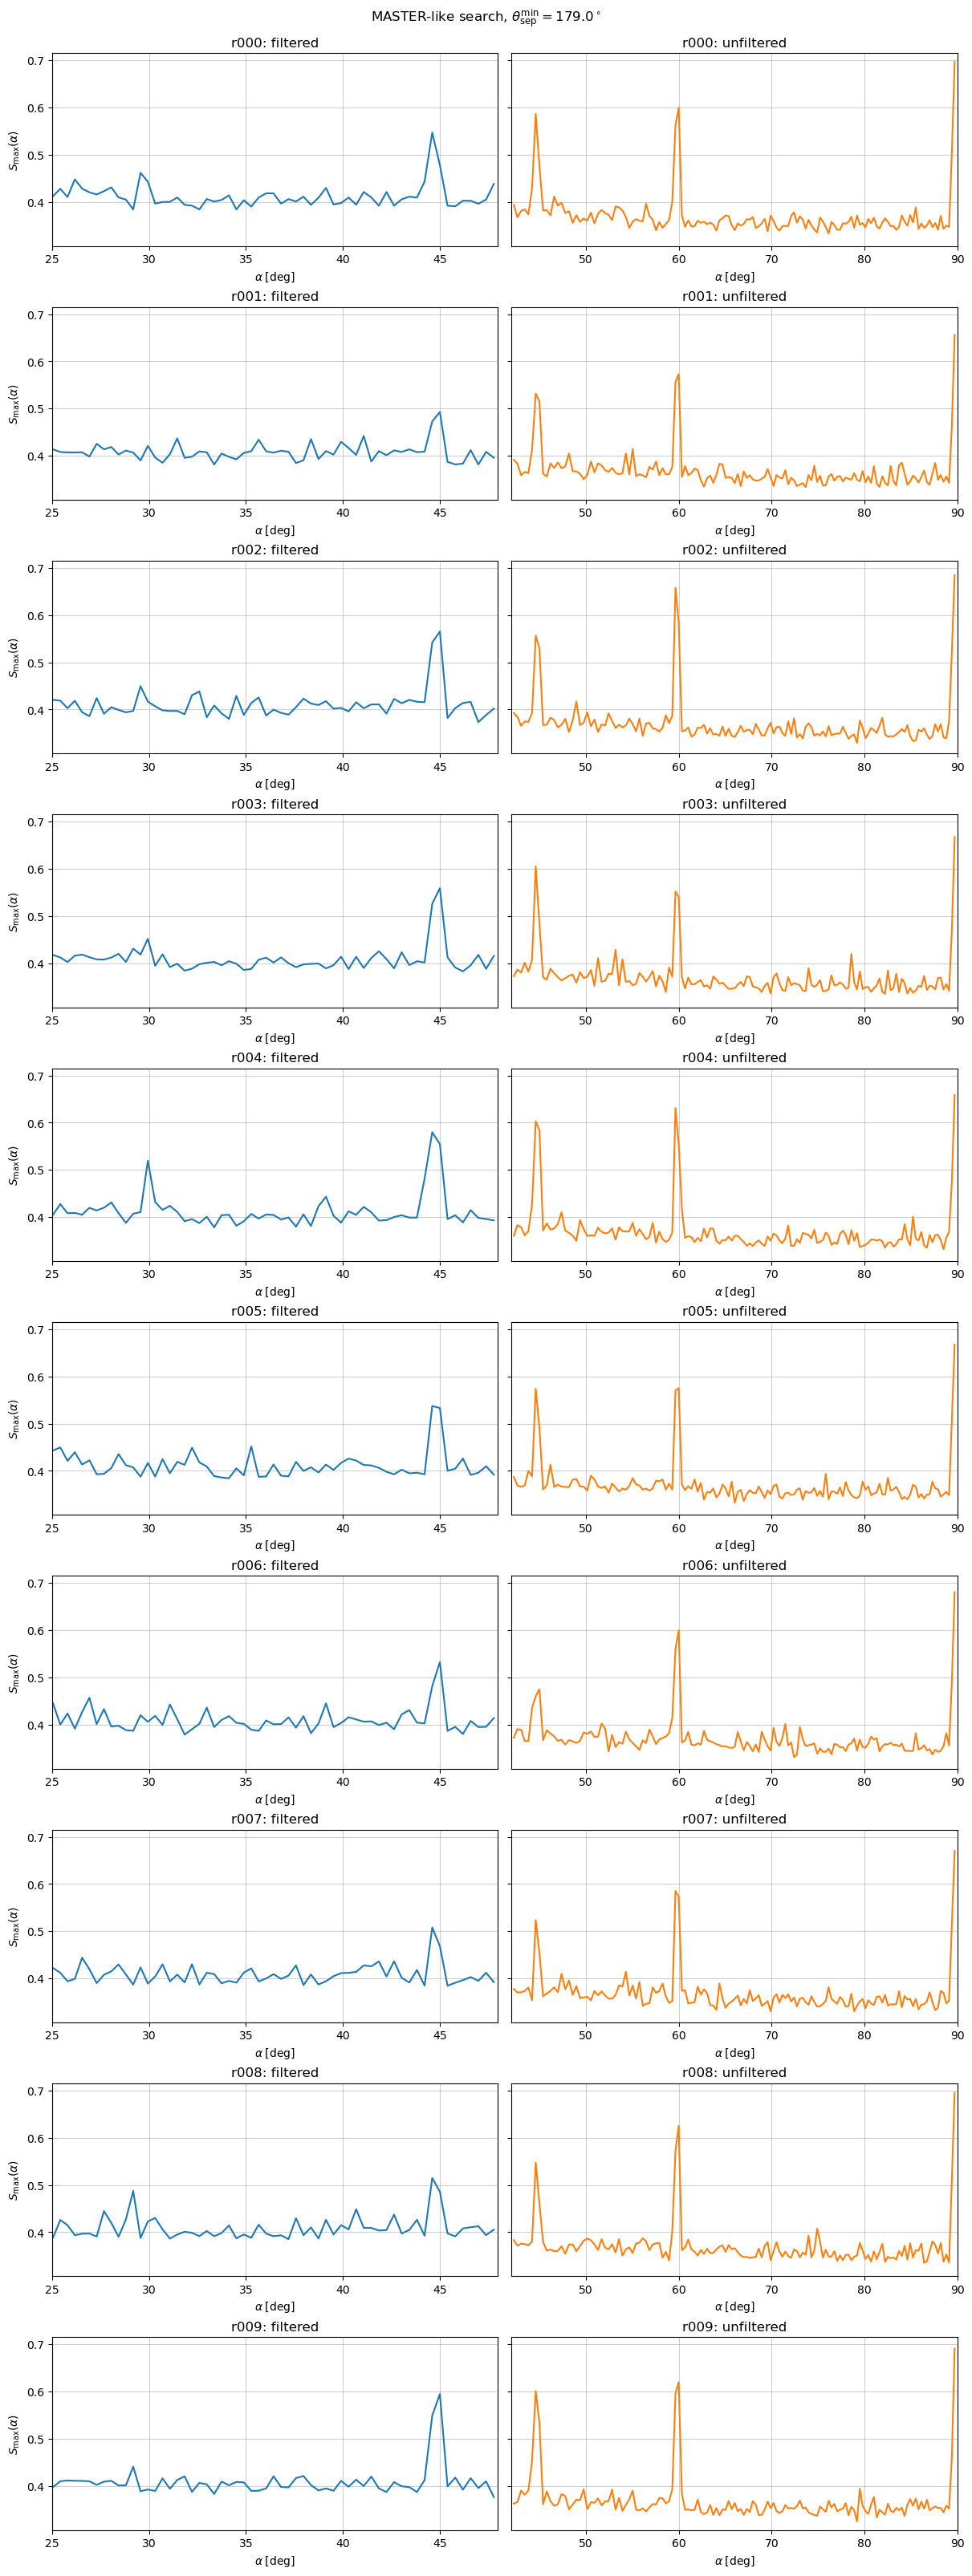

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np


# ==================================================
# Paths
# ==================================================

root = Path(
    "/hydrarepo/xluo/circles-in-the-sky"
)

result_dir = (
    root
    / "MASTER_E1_split_search"
    / "ini"
)


# ==================================================
# Create one figure containing all 20 panels
# ==================================================

fig, axes = plt.subplots(
    10,
    2,
    figsize=(12, 32),
    sharey=True,
    constrained_layout=True,
)


# ==================================================
# Plot the 10 realizations
# ==================================================

for realization in range(10):

    rr = f"{realization:03d}"

    filtered_file = (
        result_dir
        / (
            f"MASTER_E1_r{rr}"
            f"_sep179p0_filtered_mpi_0.dat"
        )
    )

    unfiltered_file = (
        result_dir
        / (
            f"MASTER_E1_r{rr}"
            f"_sep179p0_unfiltered_mpi_0.dat"
        )
    )

    filtered = np.loadtxt(
        filtered_file
    )

    unfiltered = np.loadtxt(
        unfiltered_file
    )

    filtered_axis = axes[
        realization,
        0,
    ]

    unfiltered_axis = axes[
        realization,
        1,
    ]

    filtered_axis.plot(
        filtered[:, 0],
        filtered[:, 1],
        color="tab:blue",
        linewidth=1.5,
    )

    filtered_axis.set_title(
        f"r{rr}: filtered"
    )

    filtered_axis.set_xlim(
        25.0,
        48.0,
    )

    unfiltered_axis.plot(
        unfiltered[:, 0],
        unfiltered[:, 1],
        color="tab:orange",
        linewidth=1.5,
    )

    unfiltered_axis.set_title(
        f"r{rr}: unfiltered"
    )

    unfiltered_axis.set_xlim(
        42.0,
        90.0,
    )

    for axis in (
        filtered_axis,
        unfiltered_axis,
    ):

        axis.set_xlabel(
            r"$\alpha\;[\mathrm{deg}]$"
        )

        axis.grid(
            alpha=0.6
        )

    filtered_axis.set_ylabel(
        r"$S_{\max}(\alpha)$"
    )


fig.suptitle(
    r"MASTER-like search, "
    r"$\theta_{\rm sep}^{\min}=179.0^\circ$"
)

plt.show()